# Evaluación visual: NPP-LSTM frente a Poisson

## Objetivo

Analizar la discriminación, calibración y calidad
probabilística de NPP Softplus W20 frente a Poisson.

Horizontes de evaluación:
- 1 día
- 7 días
- 30 días

Se utilizan las predicciones ya generadas en el
notebook 09, sin reentrenamiento.

Los resultados corresponden a una evaluación
histórica retrospectiva y no a un sistema
operativo de alerta sísmica.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

raiz = Path.cwd()
if not (raiz / "results").exists():
    raiz = raiz.parent

carpeta_figuras = raiz / "results" / "figuras"
carpeta_figuras.mkdir(parents=True, exist_ok=True)

pred = pd.read_csv(
    raiz / "results/predicciones_NPP_Poisson.csv"
)

pares = {}

for dias in [1, 7, 30]:

    npp = pred[
        (pred["Horizonte_dias"] == dias) &
        (pred["Modelo"] == "NPP Softplus W20")
    ].sort_values("Referencia_horas").reset_index(drop=True)

    poisson = pred[
        (pred["Horizonte_dias"] == dias) &
        (pred["Modelo"] == "Poisson")
    ].sort_values("Referencia_horas").reset_index(drop=True)

    assert np.array_equal(
        npp["Referencia_horas"].to_numpy(),
        poisson["Referencia_horas"].to_numpy()
    )

    y = npp["Observado"].to_numpy(dtype=int)
    p_npp = npp["Probabilidad"].to_numpy(dtype=float)
    p_poisson = poisson["Probabilidad"].to_numpy(dtype=float)

    assert np.array_equal(
        y, poisson["Observado"].to_numpy()
    )

    assert np.isfinite(p_npp).all()
    assert np.isfinite(p_poisson).all()
    assert np.all((p_npp >= 0) & (p_npp <= 1))
    assert np.all((p_poisson >= 0) & (p_poisson <= 1))

    pares[dias] = (y, p_npp, p_poisson)

    print(
        f"{dias} días: {len(y)} referencias, "
        f"{y.sum()} positivas"
    )

1 días: 818 referencias, 70 positivas
7 días: 818 referencias, 309 positivas
30 días: 813 referencias, 615 positivas


# Calcular ROC-AUC y Average Precision

In [2]:
filas = []

for dias, (y, p_npp, p_poisson) in pares.items():

    for nombre, probabilidades in [
        ("NPP Softplus W20", p_npp),
        ("Poisson", p_poisson)
    ]:

        filas.append({
            "Horizonte": dias,
            "Modelo": nombre,
            "ROC_AUC": roc_auc_score(
                y, probabilidades
            ),
            "Average_Precision": average_precision_score(
                y, probabilidades
            ),
            "Brier": brier_score_loss(
                y, probabilidades
            )
        })

metricas = pd.DataFrame(filas)

display(metricas.round(4))

metricas.to_csv(
    raiz / "results/metricas_roc_pr.csv",
    index=False
)

,Horizonte,Modelo,ROC_AUC,Average_Precision,Brier
0,1,NPP Softplus W20,0.7080,0.1771,0.0805
1,1,Poisson,0.5000,0.0856,0.0783
2,7,NPP Softplus W20,0.6414,0.5255,0.2871
3,7,Poisson,0.5000,0.3778,0.2406
4,30,NPP Softplus W20,0.5281,0.7866,0.2289
5,30,Poisson,0.5000,0.7565,0.2123


# Gráficos ROC

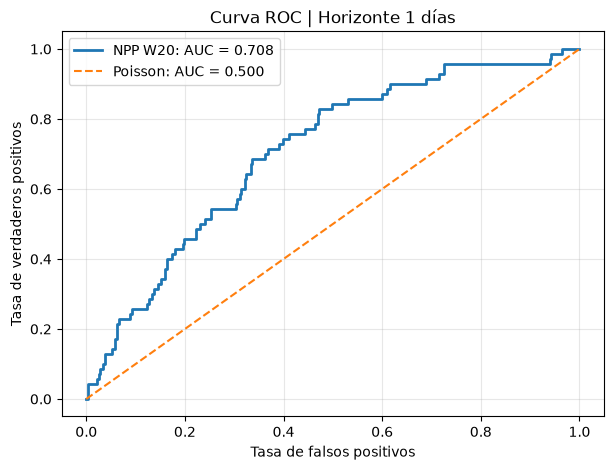

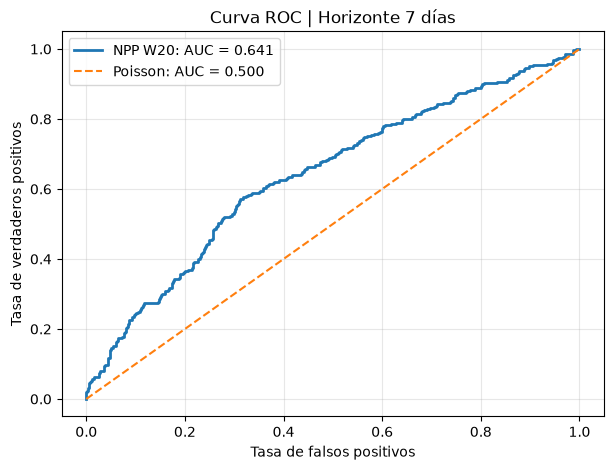

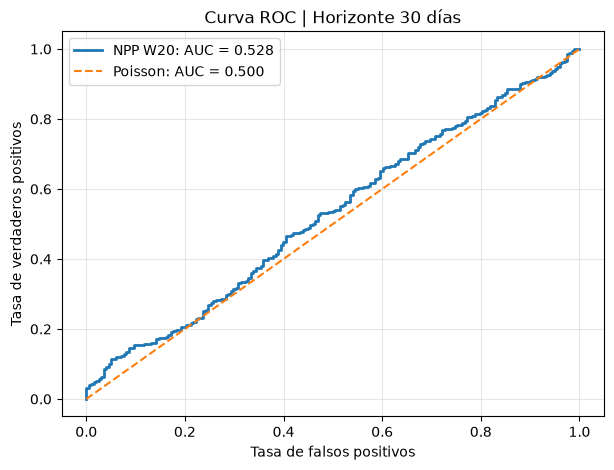

In [3]:
for dias, (y, p_npp, p_poisson) in pares.items():

    fpr, tpr, _ = roc_curve(y, p_npp)

    auc_npp = roc_auc_score(y, p_npp)
    auc_poisson = roc_auc_score(y, p_poisson)

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr, tpr,
        linewidth=2,
        label=f"NPP W20: AUC = {auc_npp:.3f}"
    )

    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        label=f"Poisson: AUC = {auc_poisson:.3f}"
    )

    plt.xlabel("Tasa de falsos positivos")
    plt.ylabel("Tasa de verdaderos positivos")

    plt.title(f"Curva ROC | Horizonte {dias} días")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.savefig(
        carpeta_figuras / f"ROC_{dias}dias.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

### Interpretación de las curvas ROC

La curva ROC permite evaluar si el modelo distingue
los periodos en los que ocurre un sismo Mw ≥ 4.5
de aquellos en los que no ocurre.

Un ROC-AUC de 0.5 indica que no existe capacidad
discriminativa, mientras que 1.0 representa una
separación perfecta.

**Resultados:**
- 1 día: NPP obtiene 0.708, mostrando cierta capacidad de distinción.
- 7 días: NPP obtiene 0.641, con una capacidad moderada.
- 30 días: NPP obtiene 0.528, muy cerca de una distinción aleatoria.

**Conclusión:** El NPP distingue mejor los periodos
positivos y negativos en horizontes cortos.
Su capacidad discriminativa disminuye a 30 días.

Estos valores no representan porcentajes de acierto.

# Gráficos Precision-Recall

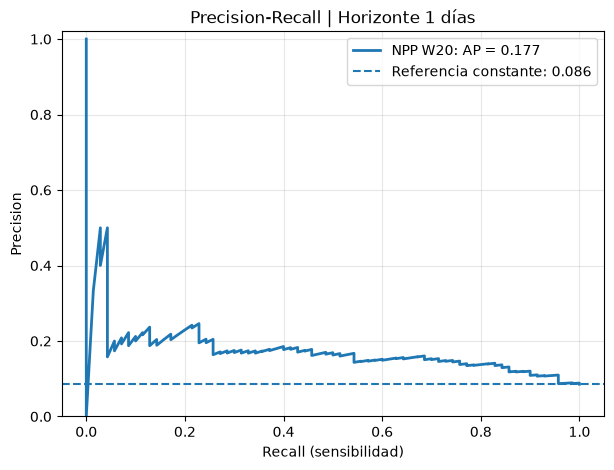

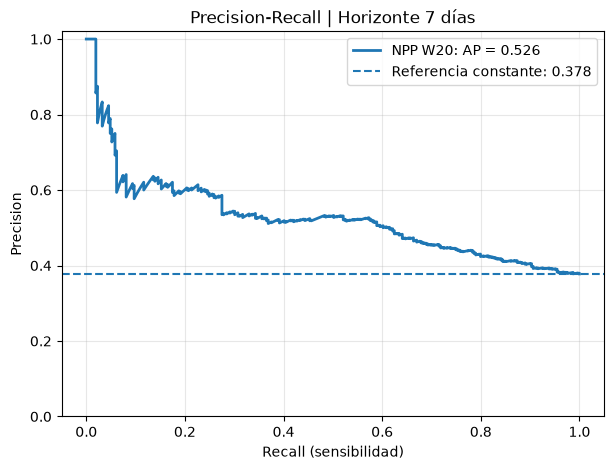

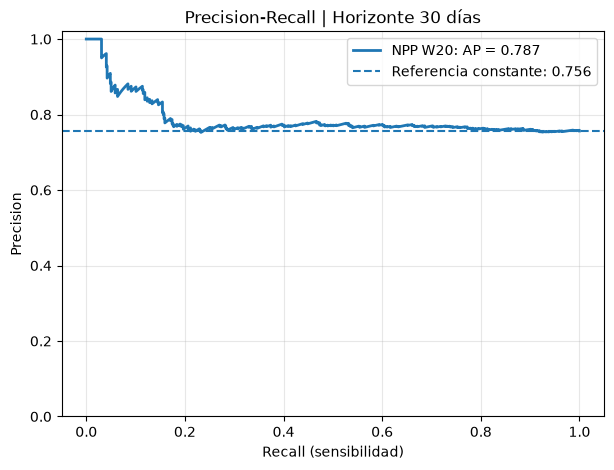

In [4]:
for dias, (y, p_npp, p_poisson) in pares.items():

    precision, recall, _ = precision_recall_curve(
        y, p_npp
    )

    ap_npp = average_precision_score(y, p_npp)

    prevalencia = y.mean()

    plt.figure(figsize=(7, 5))

    plt.plot(
        recall, precision,
        linewidth=2,
        label=f"NPP W20: AP = {ap_npp:.3f}"
    )

    plt.axhline(
        prevalencia,
        linestyle="--",
        label=f"Referencia constante: {prevalencia:.3f}"
    )

    plt.xlabel("Recall (sensibilidad)")
    plt.ylabel("Precision")

    plt.title(
        f"Precision-Recall | Horizonte {dias} días"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.ylim(0, 1.02)

    plt.savefig(
        carpeta_figuras / f"PR_{dias}dias.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

### Interpretación de Precision-Recall

Esta curva muestra el equilibrio entre detectar los
periodos con sismos y evitar predicciones positivas
que no se cumplen.

- Precision: proporción de predicciones positivas
  que realmente tuvieron un sismo.
- Recall: proporción de periodos con sismos
  que el modelo consiguió identificar.

El indicador Average Precision (AP) resume
el comportamiento de esta curva. Cuanto mayor,
mejor es la capacidad de ordenar los casos positivos.

**Resultados NPP:**
- 1 día: AP = 0.177
- 7 días: AP = 0.526
- 30 días: AP = 0.787

**Conclusión:** El NPP puede detectar muchos periodos
positivos, pero también produce numerosos falsos positivos.

Un AP elevado no significa necesariamente que
las probabilidades del modelo estén bien calibradas.

# Gráficos de calibración

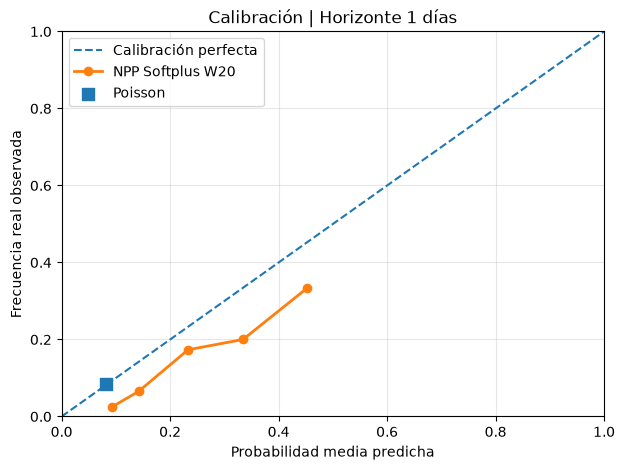

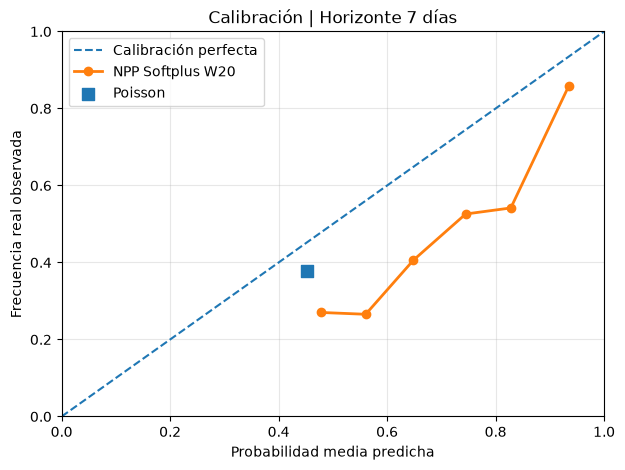

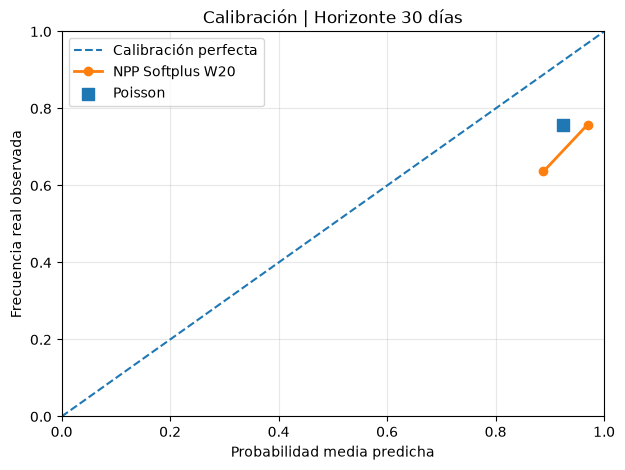

In [5]:
for dias, (y, p_npp, p_poisson) in pares.items():

    frecuencia, confianza = calibration_curve(
        y,
        p_npp,
        n_bins=10,
        strategy="uniform"
    )

    plt.figure(figsize=(7, 5))

    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        label="Calibración perfecta"
    )

    plt.plot(
        confianza,
        frecuencia,
        marker="o",
        linewidth=2,
        label="NPP Softplus W20"
    )

    # Poisson tiene una probabilidad constante
    plt.scatter(
        [p_poisson.mean()],
        [y.mean()],
        marker="s",
        s=80,
        label="Poisson"
    )

    plt.xlabel("Probabilidad media predicha")
    plt.ylabel("Frecuencia real observada")

    plt.title(
        f"Calibración | Horizonte {dias} días"
    )

    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(alpha=0.3)

    plt.savefig(
        carpeta_figuras / f"Calibracion_{dias}dias.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

### Interpretación de la calibración

La calibración permite comprobar si las probabilidades
estimadas por el modelo coinciden con la frecuencia
real de ocurrencia de los sismos.

La línea diagonal representa una calibración perfecta.

- Puntos sobre la línea: probabilidades bien calibradas.
- Puntos por debajo: el modelo sobreestima la ocurrencia.
- Puntos por encima: el modelo subestima la ocurrencia.

**Resultados:**
En el horizonte de 30 días, el NPP estima una
probabilidad media del 96.84 %, pero la frecuencia
real observada fue de aproximadamente 75.65 %.

**Conclusión:** El NPP presenta sobreestimación
de probabilidades, especialmente a largo plazo.

Por tanto, sus probabilidades deben interpretarse
como resultados experimentales y no como alertas
sísmicas confiables.

# Comparación visual de Brier Score

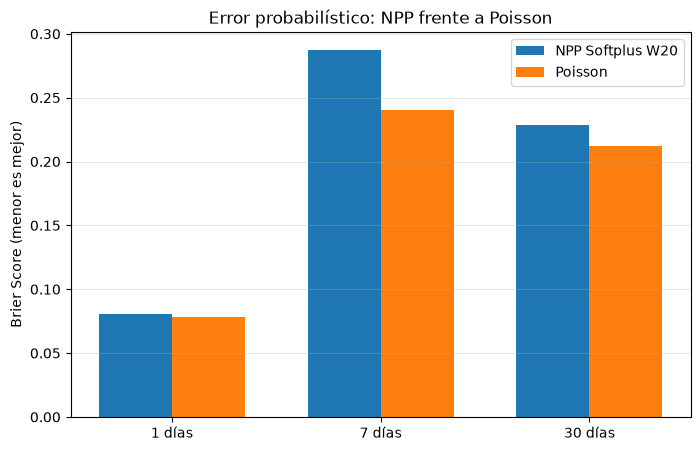

In [6]:
res = pd.read_csv(
    raiz / "results/comparacion_NPP_Poisson.csv"
)

dias = np.array([1, 7, 30])
brier_npp = []
brier_poisson = []

for d in dias:
    grupo = res[res["Horizonte_dias"] == d]

    brier_npp.append(
        grupo.loc[
            grupo["Modelo"] == "NPP Softplus W20",
            "Brier"
        ].iloc[0]
    )

    brier_poisson.append(
        grupo.loc[
            grupo["Modelo"] == "Poisson",
            "Brier"
        ].iloc[0]
    )

x = np.arange(len(dias))
ancho = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - ancho / 2,
    brier_npp,
    width=ancho,
    label="NPP Softplus W20"
)

plt.bar(
    x + ancho / 2,
    brier_poisson,
    width=ancho,
    label="Poisson"
)

plt.xticks(x, [f"{d} días" for d in dias])
plt.ylabel("Brier Score (menor es mejor)")
plt.title("Error probabilístico: NPP frente a Poisson")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    carpeta_figuras / "Comparacion_Brier.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Interpretación del Brier Score

El Brier Score mide el error entre las probabilidades
estimadas y los resultados realmente observados.

Su valor ideal es 0. Cuanto menor sea, mejor.

**Resultados:**

| Horizonte | NPP | Poisson |
|---|---|---|
| 1 día | 0.0805 | 0.0783 |
| 7 días | 0.2871 | 0.2406 |
| 30 días | 0.2289 | 0.2123 |

**Conclusión:** Poisson obtiene menor error
probabilístico en los tres horizontes evaluados.

Aunque el NPP consigue distinguir determinados
periodos positivos y negativos, sus probabilidades
son menos precisas que las del modelo Poisson.

Esto demuestra que un modelo más complejo no
necesariamente produce mejores estimaciones.

## Conclusiones de la evaluación visual

El modelo NPP-LSTM con Softplus y ventana de 20 eventos
presenta cierta capacidad para diferenciar periodos
con y sin sismos de magnitud Mw ≥ 4.5.

Los resultados ROC-AUC muestran su mayor capacidad
discriminativa en horizontes cortos. Sin embargo,
las curvas Precision-Recall evidencian que esta
detección puede acompañarse de numerosos falsos positivos.

Por otro lado, el análisis de calibración muestra
que el NPP tiende a sobreestimar las probabilidades
de ocurrencia sísmica.

El modelo Poisson, aunque no distingue entre fechas
individuales porque utiliza una tasa constante,
obtiene mejores valores de Brier Score.

**Conclusión general:**
La arquitectura NPP-LSTM demuestra capacidad de
aprendizaje, pero no supera al modelo Poisson en
calidad probabilística bajo el protocolo evaluado.

Los resultados son retrospectivos y exploratorios;
no constituyen un sistema operativo de predicción
o alerta sísmica.